In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
os.makedirs('figures', exist_ok=True)

In [2]:
df = pd.read_csv('data/processed/t1d_phase3_trials_2026-10-24.csv')

In [3]:
# Confirm that the dataset has the expected number of trials and print the counts of each status
print(f"Trials in dataset: {len(df)}")
print(df['status'].value_counts())

# Count each status
completed  = (df['status'] == 'COMPLETED').sum()
terminated = (df['status'] == 'TERMINATED').sum()
withdrawn  = (df['status'] == 'WITHDRAWN').sum()
unknown    = (df['status'] == 'UNKNOWN').sum()
running    = df['status'].isin(['RECRUITING', 'ACTIVE_NOT_RECRUITING', 'NOT_YET_RECRUITING']).sum()

print(f"\nStill running: {running}")
print(f"Unknown: {unknown} ({unknown / len(df):.1%} of dataset)")

# Metric 1: terminated after enrollment (withdrawn excluded)
m1_fail  = terminated
m1_total = completed + terminated
m1       = m1_fail / m1_total
m1_best  = m1_fail / (m1_total + unknown)              # all unknowns completed
m1_worst = (m1_fail + unknown) / (m1_total + unknown)  # all unknowns failed

# Metric 2: didn't finish as planned (terminated + withdrawn)
m2_fail  = terminated + withdrawn
m2_total = completed + terminated + withdrawn
m2       = m2_fail / m2_total
m2_best  = m2_fail / (m2_total + unknown)
m2_worst = (m2_fail + unknown) / (m2_total + unknown)

print(f"Terminated after enrollment (withdrawn excluded): {m1:.1%} ({m1_fail} of {m1_total}) | range {m1_best:.1%} – {m1_worst:.1%}")
print(f"Didn't finish as planned (terminated + withdrawn): {m2:.1%} ({m2_fail} of {m2_total}) | range {m2_best:.1%} – {m2_worst:.1%}")

Trials in dataset: 355
status
COMPLETED                264
TERMINATED                27
RECRUITING                19
UNKNOWN                   18
WITHDRAWN                 11
ACTIVE_NOT_RECRUITING     10
NOT_YET_RECRUITING         6
Name: count, dtype: int64

Still running: 35
Unknown: 18 (5.1% of dataset)
Terminated after enrollment (withdrawn excluded): 9.3% (27 of 291) | range 8.7% – 14.6%
Didn't finish as planned (terminated + withdrawn): 12.6% (38 of 302) | range 11.9% – 17.5%


In [4]:
# Analyze the distribution of last_update dates by status
print("Unknown")
print(f'Oldest last_update: {df[df['status'] == 'UNKNOWN']['last_update'].min()}')
print(f'Newest last_update: {df[df['status'] == 'UNKNOWN']['last_update'].max()}')
print(f'Median last_update: {pd.to_datetime(df[df['status'] == 'UNKNOWN']['last_update']).median()}')
print('Non-unknown')
print(f'Oldest last_update: {df[df['status'] == 'COMPLETED']['last_update'].min()}')
print(f'Newest last_update: {df[df['status'] == 'COMPLETED']['last_update'].max()}')
print(f'Median last_update: {pd.to_datetime(df[df['status'] == 'COMPLETED']['last_update']).median()}')


Unknown
Oldest last_update: 2006-09-18
Newest last_update: 2024-04-16
Median last_update: 2015-04-14 00:00:00
Non-unknown
Oldest last_update: 2006-07-04
Newest last_update: 2026-07-08
Median last_update: 2017-03-03 00:00:00


In [5]:
# read the gold standard labels for stop reasons and filter the dataset to only include trials that were terminated or withdrawn
gold = pd.read_csv('data/labels/stop_reasons_gold.csv')
df_stop = df[df['status'].isin(['TERMINATED','WITHDRAWN'])]
len(df_stop)

38

#### Proportion of stop reasons

In [6]:
# Merge the gold standard labels with the filtered dataset and calculate the percentage of each stop reason category
stop_labeled = pd.merge(df_stop,gold,how = 'left',on='nct_id')
round(stop_labeled['category'].value_counts(dropna=False,normalize=True)*100,2)


category
Business               39.47
Unclear                31.58
Efficacy               15.79
Funding / resources     7.89
Regulatory              2.63
Enrollment              2.63
Name: proportion, dtype: float64

#### Inhaled Insulin

In [7]:
# Text to search: brief summary + detailed description (blanks become empty strings)
inhale_text = df['brief_summary'].fillna('') + ' ' + df['detailed_description'].fillna('')
inhale_pattern = 'inhal|exubera|aerx|technosphere|afrezza'

df['is_inhaled'] = inhale_text.str.contains(inhale_pattern, case=False)
tot_inhale = df['is_inhaled'].sum()

stop_labeled = stop_labeled.merge(df[['nct_id', 'is_inhaled']], on='nct_id', how='left')
inhale_stop = stop_labeled[stop_labeled['is_inhaled']]
inhale_stop_count = len(inhale_stop)

print(f"{tot_inhale} trials in the dataset involved inhaled insulin.")
print(f"{inhale_stop_count} of them were terminated or withdrawn "
      f"({inhale_stop_count / tot_inhale:.1%} of inhaled-insulin trials; "
      f"{inhale_stop_count / len(stop_labeled):.1%} of all stopped trials).")

inhale_stop[['nct_id', 'lead_sponsor_name', 'category']]

28 trials in the dataset involved inhaled insulin.
15 of them were terminated or withdrawn (53.6% of inhaled-insulin trials; 39.5% of all stopped trials).


,nct_id,lead_sponsor_name,category
1,NCT00523042,Novo Nordisk A/S,Business
2,NCT00539409,Florida Atlantic University,Unclear
7,NCT00332826,Mannkind Corporation,Business
9,NCT00642616,Mannkind Corporation,Unclear
10,NCT00700622,Mannkind Corporation,Business
13,NCT00138671,Pfizer,Business
18,NCT00322257,Novo Nordisk A/S,Business
21,NCT00472953,Novo Nordisk A/S,Business
24,NCT00287066,Pfizer,Business
26,NCT00228891,Florida Atlantic University,Unclear


In [8]:
# Categorize sponsors into 'Industry' and 'Non-industry' groups for both the full dataset and the stopped trials subset
stop_labeled['sponsor_group'] = 'Non-industry'
stop_labeled.loc[stop_labeled['sponsor_class'] == 'INDUSTRY', 'sponsor_group'] = 'Industry'

df['sponsor_group'] = 'Non-industry'
df.loc[df['sponsor_class'] == 'INDUSTRY', 'sponsor_group'] = 'Industry'

In [9]:
# Calculate termination rates by sponsor group
rates = {}
for group, status in df.groupby('sponsor_group'):
    completed = (status['status'] == 'COMPLETED').sum()
    terminated = (status['status'] == 'TERMINATED').sum()
    withdrawn = (status['status'] == 'WITHDRAWN').sum()

    proportion_terminated = terminated / (completed + terminated)
    proportion_terminated_withdrawn = (terminated + withdrawn) / (completed + terminated + withdrawn)

    rates[group] = proportion_terminated * 100

    print(f"{group} ({len(status)} trials):")
    print(f"  Proportion terminated: {proportion_terminated:.1%} ({terminated} of {completed + terminated})")
    print(f"  Proportion terminated or withdrawn: {proportion_terminated_withdrawn:.1%} "
          f"({terminated + withdrawn} of {completed + terminated + withdrawn})\n")


Industry (203 trials):
  Proportion terminated: 10.3% (19 of 185)
  Proportion terminated or withdrawn: 13.1% (25 of 191)

Non-industry (152 trials):
  Proportion terminated: 7.5% (8 of 106)
  Proportion terminated or withdrawn: 11.7% (13 of 111)



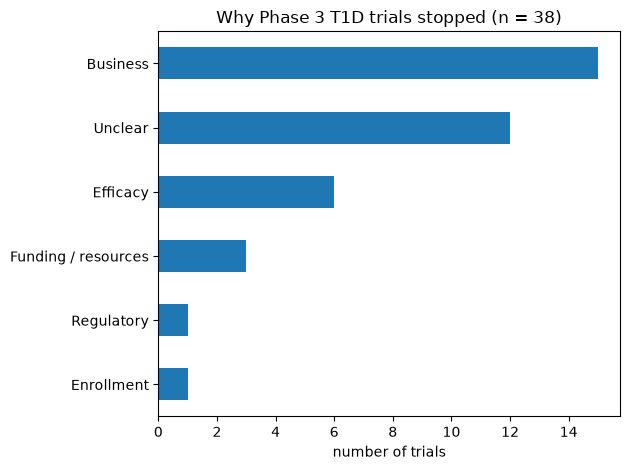

In [10]:
# create a horizontal bar plot of the reasons for stopping trials
ax = stop_labeled['category'].value_counts().sort_values().plot(kind = 'barh')
ax.set_xlabel('number of trials')
ax.set_ylabel('')
ax.set_title('Why Phase 3 T1D trials stopped (n = 38)')
plt.tight_layout()
plt.savefig('figures/stop_reasons.png', dpi=150)
plt.show()

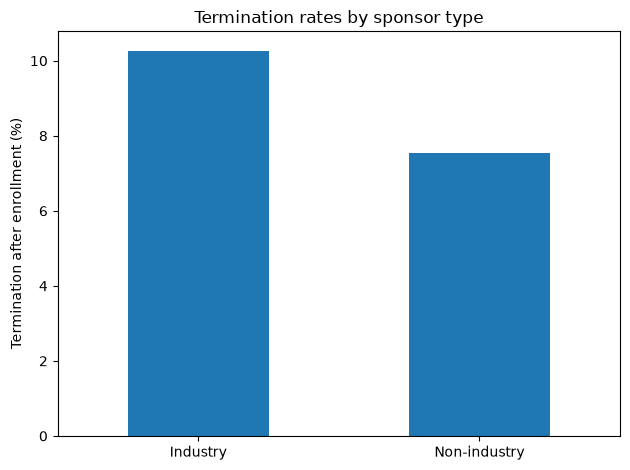

In [11]:
# create a bar plot of termination rates by sponsor type
ax = pd.Series(rates).plot(kind = 'bar', rot = 0)
ax.set_ylabel('Termination after enrollment (%)')
ax.set_title('Termination rates by sponsor type')
plt.tight_layout()
plt.savefig('figures/termination_rates_by_sponsor.png', dpi=150)
plt.show()